# 06: Prompt Tuning — Learning to Steer Frozen Models

> Part of the [SLM Fine-Tuning Tutorial](https://github.com/Kumarjit-Pathak/finetuning-slm)

**What you'll learn**: How to adapt a **completely frozen** language model using only a handful of learnable soft-prompt embeddings prepended to the input — no gradient flows into the model weights at all.

**Key insight**: Instead of updating millions of parameters, we learn `k × hidden_size` numbers (often < 0.01% of model params) that steer the frozen model toward a target task.

| Technique | Trainable | Model frozen? | Typical use |
|---|---|---|---|
| Full fine-tune | 100% | ❌ | Max quality, large data |
| LoRA | 0.1–1% | ❌ | Best PEFT balance |
| **Prompt Tuning** | **< 0.01%** | **✅ 100%** | **Multi-task, tiny footprint** |
| Prefix Tuning | 0.01–0.1% | ✅ | Next notebook |

In [1]:
# Colab check & package install
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run(
        ["pip", "install", "-q", "transformers>=4.40", "peft>=0.10", "datasets"],
        check=True,
    )
    print("✅ Colab packages installed")
else:
    print("✅ Running locally — using project virtual environment")

✅ Running locally — using project virtual environment


In [2]:
import os, gc, time, warnings

# Force offline mode to avoid SSL/proxy issues with HuggingFace Hub
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_HUB_OFFLINE"] = "1"

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import (
    PromptTuningConfig, PromptTuningInit, get_peft_model, TaskType,
    LoraConfig,
)
warnings.filterwarnings("ignore")

# ── Device ──────────────────────────────────────────────────────────────────────
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
print(f"Device : {DEVICE}")

# ── Model fallback (360M preferred, 135M if not cached) ─────────────────────────
_HUB_CACHE = os.path.expanduser("~/.cache/huggingface/hub")
_HAVE_360M = os.path.isdir(
    os.path.join(_HUB_CACHE, "models--HuggingFaceTB--SmolLM2-360M-Instruct")
)
MODEL_NAME = (
    "HuggingFaceTB/SmolLM2-360M-Instruct"
    if _HAVE_360M
    else "HuggingFaceTB/SmolLM2-135M-Instruct"
)
print(f"Model  : {MODEL_NAME}" + ("" if _HAVE_360M else " ⚠️  360M not cached — falling back to 135M"))

# ── Memory helpers ────────────────────────────────────────────────────────────
def get_mem_gb():
    if DEVICE.type == "mps":    return torch.mps.current_allocated_memory() / 1e9
    elif DEVICE.type == "cuda": return torch.cuda.memory_allocated() / 1e9
    return 0.0

def free_memory(*models):
    for m in models:
        try: del m
        except: pass
    gc.collect()
    if DEVICE.type == "mps":    torch.mps.empty_cache()
    elif DEVICE.type == "cuda": torch.cuda.empty_cache()

import peft
print(f"PyTorch : {torch.__version__}")
print(f"PEFT    : {peft.__version__}")

Device : mps
Model  : HuggingFaceTB/SmolLM2-135M-Instruct ⚠️  360M not cached — falling back to 135M
PyTorch : 2.13.0
PEFT    : 0.19.1


## 🗂️ Dataset

We reuse the same **instruction-following** setup from previous notebooks: 16 short Q&A pairs in ChatML format, repeated to form a training set.

**Why keep the model frozen?**  
That's the entire point of prompt tuning! The soft prompts must learn to *steer* the frozen model's existing knowledge rather than modify it:

- ✅ Zero catastrophic forgetting (weights never change)
- ✅ One model, many tasks (swap the prompt, not the weights)  
- ✅ Storage: only `k × hidden_size` floats per task (e.g. 20 × 576 = **11,520 numbers** for 135M)
- ⚠️  Works best at billion-scale; tiny models have less "steerable" capacity

In [3]:
class InstructDataset(Dataset):
    """Tiny instruction-following dataset in ChatML format."""
    EXAMPLES = [
        ("What is machine learning?",
         "Machine learning enables systems to learn patterns from data without explicit programming."),
        ("Explain neural networks.",
         "Neural networks are layered computing systems loosely inspired by biological brain structure."),
        ("What is overfitting?",
         "Overfitting occurs when a model memorizes training data and fails to generalize to new examples."),
        ("Define gradient descent.",
         "Gradient descent minimizes a loss function by iteratively stepping in the negative gradient direction."),
        ("What is a transformer?",
         "A transformer uses self-attention to process all tokens in parallel, replacing sequential recurrence."),
        ("Explain fine-tuning.",
         "Fine-tuning adapts a pretrained model to a downstream task using task-specific labeled data."),
        ("What is regularization?",
         "Regularization adds constraints or penalties to prevent overfitting and improve generalization."),
        ("Define backpropagation.",
         "Backpropagation applies the chain rule to propagate gradients backward through network layers."),
        ("What is attention?",
         "Attention lets each token dynamically weight the relevance of every other token in the sequence."),
        ("Explain tokenization.",
         "Tokenization converts raw text into integer IDs that can be processed by neural networks."),
        ("What is a loss function?",
         "A loss function quantifies the discrepancy between model predictions and true labels."),
        ("What is transfer learning?",
         "Transfer learning reuses representations learned on a large task to improve learning on smaller ones."),
        ("Define batch normalization.",
         "Batch normalization normalizes activations across a mini-batch to stabilize and accelerate training."),
        ("What is dropout?",
         "Dropout randomly deactivates neurons during training to prevent co-adaptation and reduce overfitting."),
        ("Explain embeddings.",
         "Embeddings map discrete tokens to dense continuous vectors in a learned semantic representation space."),
        ("What is RLHF?",
         "RLHF aligns language model outputs with human preferences using a reward model trained on feedback."),
    ]

    def __init__(self, tokenizer, max_len: int = 128, repeat: int = 4, n: int = None):
        self.tokenizer = tokenizer
        self.max_len = max_len
        data = self.EXAMPLES * repeat
        if n:
            data = data[:n]
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        q, a = self.data[idx]
        text = (
            f"<|im_start|>user\n{q}<|im_end|>\n"
            f"<|im_start|>assistant\n{a}<|im_end|>"
        )
        enc = self.tokenizer(
            text,
            max_length=self.max_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )
        ids = enc["input_ids"].squeeze()
        return {"input_ids": ids, "labels": ids.clone()}


# ── Load tokenizer ─────────────────────────────────────────────────────────────
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, local_files_only=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

train_ds = InstructDataset(tokenizer, max_len=128, repeat=4)
val_ds   = InstructDataset(tokenizer, max_len=128, repeat=1, n=16)
print(f"Train: {len(train_ds)} samples | Val: {len(val_ds)} samples")
sample = tokenizer.decode(train_ds[0]["input_ids"][:30].tolist(), skip_special_tokens=False)
print(f"Sample (first 30 tokens): {sample!r}")

Train: 64 samples | Val: 16 samples
Sample (first 30 tokens): '<|im_start|>user\nWhat is machine learning?<|im_end|>\n<|im_start|>assistant\nMachine learning enables systems to learn patterns from data without explicit programming.<|im_end|><|im_end|><|im_end|>'


## 🧠 How Prompt Tuning Works

```
Normal input (every forward pass):

  [user_tok] [question...] [asst_tok] [answer...]
       ↓           ↓             ↓          ↓
  Embedding    Embedding    Embedding   Embedding
       ↓           ↓             ↓          ↓
  ┌────────────────────────────────────────────┐
  │              Frozen LLM                   │
  └────────────────────────────────────────────┘

Prompt Tuning — LEARNED prefix prepended:

  [soft_1] ... [soft_k]  [user_tok] [question...] [asst_tok] [answer...]
      ↓             ↓         ↓          ↓              ↓          ↓
  LEARNED       LEARNED   Embedding  Embedding      Embedding  Embedding
  emb_1         emb_k         ↓          ↓              ↓          ↓
      └────┬──────┘       ┌──────────────────────────────────────────┐
    Only these            │           Frozen LLM (100% frozen)       │
    k embeddings          └──────────────────────────────────────────┘
    have gradients!
```

### Parameter count

| Config | Formula | Value |
|---|---|---|
| 135M model, 20 soft tokens | 20 × 576 | **11,520 params** (0.009%) |
| 135M model, 50 soft tokens | 50 × 576 | **28,800 params** (0.021%) |
| 360M model, 20 soft tokens | 20 × 960 | **19,200 params** (0.005%) |

### Initialization: TEXT vs RANDOM

- **TEXT init**: Initialize soft-prompt embeddings from actual token embeddings of a descriptive string  
  → Faster convergence, better starting point  
- **RANDOM init**: Initialize with random embeddings  
  → Slower convergence, may need more tokens/epochs

The soft prompts learn to activate *task-relevant circuits* already latent in the frozen model.

In [4]:
INIT_TEXT = "Answer the following question clearly and concisely:"


def run_prompt_tuning_experiment(
    num_virtual_tokens: int = 20,
    prompt_init: str = "TEXT",
    init_text: str = INIT_TEXT,
    num_epochs: int = 8,
    lr: float = 3e-3,
    batch_size: int = 8,
    label: str = None,
):
    """Train soft-prompt embeddings on a fully frozen model; return metrics dict."""
    t0 = time.time()

    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, torch_dtype=torch.float32, local_files_only=True
    )

    # ── PromptTuningConfig ─────────────────────────────────────────────────────
    init_enum = PromptTuningInit.TEXT if prompt_init == "TEXT" else PromptTuningInit.RANDOM
    pt_cfg = PromptTuningConfig(
        task_type=TaskType.CAUSAL_LM,
        num_virtual_tokens=num_virtual_tokens,
        prompt_tuning_init=init_enum,
        prompt_tuning_init_text=init_text if prompt_init == "TEXT" else None,
        tokenizer_name_or_path=MODEL_NAME if prompt_init == "TEXT" else None,
    )
    model = get_peft_model(base, pt_cfg)
    model.to(DEVICE)

    # Count trainable vs total parameters
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    pct       = 100 * trainable / total
    mem_loaded = get_mem_gb()

    # ── Training loop ──────────────────────────────────────────────────────────
    loader     = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds,   batch_size=8,          shuffle=False)
    optimizer  = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )

    train_losses, val_losses = [], []
    for epoch in range(num_epochs):
        model.train()
        ep_loss = 0.0
        for batch in loader:
            ids    = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            loss   = model(input_ids=ids, labels=labels).loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], 1.0
            )
            optimizer.step()
            ep_loss += loss.item()
        train_losses.append(ep_loss / len(loader))

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for batch in val_loader:
                ids    = batch["input_ids"].to(DEVICE)
                labels = batch["labels"].to(DEVICE)
                vl += model(input_ids=ids, labels=labels).loss.item()
        val_losses.append(vl / len(val_loader))

    elapsed = time.time() - t0
    lbl = label or f"PT-{num_virtual_tokens}tok-{prompt_init}"
    result = {
        "label":              lbl,
        "num_virtual_tokens": num_virtual_tokens,
        "prompt_init":        prompt_init,
        "trainable_params":   trainable,
        "total_params":       total,
        "pct_trainable":      pct,
        "train_losses":       train_losses,
        "val_losses":         val_losses,
        "val_loss":           val_losses[-1],
        "elapsed":            elapsed,
        "mem_gb":             mem_loaded,
    }
    print(
        f"[{lbl:<22}] val_loss={result['val_loss']:.4f} | "
        f"trainable={trainable:>8,} ({pct:.4f}%) | "
        f"{elapsed:.1f}s | {mem_loaded:.2f}GB"
    )
    free_memory(model, base)
    return result


# ── Standard run: 20 virtual tokens, TEXT init ────────────────────────────────
print("=" * 72)
print("Standard Prompt Tuning — 20 virtual tokens, TEXT initialization")
print("=" * 72)
pt_standard = run_prompt_tuning_experiment(
    num_virtual_tokens=20,
    prompt_init="TEXT",
    init_text=INIT_TEXT,
    num_epochs=8,
    label="PT-20tok-TEXT",
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Standard Prompt Tuning — 20 virtual tokens, TEXT initialization


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[PT-20tok-TEXT         ] val_loss=0.3458 | trainable=  11,520 (0.0086%) | 16.3s | 0.54GB


## 🔢 Virtual Token Count: Finding the Sweet Spot

How many soft-prompt tokens do you need?

| Range | Behaviour |
|---|---|
| **2–5 tokens** | Under-steers — model can't learn a useful direction |
| **10–20 tokens** | Sweet spot for most tasks |
| **50+ tokens** | Diminishing returns; inference prefills extra context each step |

We run three extra configs (`2`, `10`, `50` tokens) and compare them against the standard `20`-token run above.

In [5]:
print("Token count sweep: 2, 10, 50 virtual tokens (TEXT init)")
print("=" * 72)

sweep_configs = [
    (2,  "TEXT", "PT-2tok-TEXT"),
    (10, "TEXT", "PT-10tok-TEXT"),
    (50, "TEXT", "PT-50tok-TEXT"),
]

sweep_results = []
for n_tok, init_type, lbl in sweep_configs:
    r = run_prompt_tuning_experiment(
        num_virtual_tokens=n_tok,
        prompt_init=init_type,
        init_text=INIT_TEXT,
        num_epochs=8,
        label=lbl,
    )
    sweep_results.append(r)

# Include the standard 20-tok result for a full 4-point comparison
all_tok_results = [sweep_results[0], sweep_results[1], pt_standard, sweep_results[2]]

print()
print(f"{'Label':<22} {'Tokens':>6} {'Trainable Params':>18} {'Val Loss':>10} {'Time':>7}")
print("-" * 70)
for r in all_tok_results:
    print(
        f"{r['label']:<22} {r['num_virtual_tokens']:>6} "
        f"{r['trainable_params']:>18,} {r['val_loss']:>10.4f} {r['elapsed']:>6.1f}s"
    )

Token count sweep: 2, 10, 50 virtual tokens (TEXT init)


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[PT-2tok-TEXT          ] val_loss=0.6878 | trainable=   1,152 (0.0009%) | 13.0s | 0.54GB


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[PT-10tok-TEXT         ] val_loss=0.4028 | trainable=   5,760 (0.0043%) | 13.2s | 0.54GB


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[PT-50tok-TEXT         ] val_loss=0.3210 | trainable=  28,800 (0.0214%) | 16.8s | 0.54GB

Label                  Tokens   Trainable Params   Val Loss    Time
----------------------------------------------------------------------
PT-2tok-TEXT                2              1,152     0.6878   13.0s
PT-10tok-TEXT              10              5,760     0.4028   13.2s
PT-20tok-TEXT              20             11,520     0.3458   16.3s
PT-50tok-TEXT              50             28,800     0.3210   16.8s


## 🔴 Failure Points

Two classic prompt-tuning failure modes:

### Failure 1 — Too few virtual tokens (`num_virtual_tokens=2`)
With only 2 learnable vectors, the soft prompt can't encode enough task signal to steer the frozen model.  
We already captured this above — compare `PT-2tok-TEXT` vs `PT-20tok-TEXT`.

### Failure 2 — RANDOM initialization
Starting from random embeddings instead of meaningful token embeddings means:
- The optimizer starts from a *random* direction in embedding space
- Convergence is slower and final quality is often worse
- Especially harmful at very low token counts

We demonstrate RANDOM init below and compare against TEXT init (same 20 tokens).

In [6]:
print("Failure demo — RANDOM init vs TEXT init (20 virtual tokens)")
print("=" * 72)

pt_random = run_prompt_tuning_experiment(
    num_virtual_tokens=20,
    prompt_init="RANDOM",
    num_epochs=8,
    label="PT-20tok-RANDOM",
)

# Compare
pt_2tok = sweep_results[0]  # PT-2tok-TEXT

print()
print("─── Failure Analysis ───────────────────────────────────────────────────")
print(f"{'Config':<24} {'Init':>6} {'Tokens':>6} {'Val Loss':>10} {'vs Standard':>14}")
print("-" * 65)
for r, note in [
    (pt_2tok,    "Too few tokens → can't steer frozen model"),
    (pt_random,  "Random init → poor starting point"),
    (pt_standard,"✅ TEXT init, 20 tokens → recommended"),
]:
    delta = r["val_loss"] - pt_standard["val_loss"]
    arrow = f"+{delta:.4f}" if delta > 0 else f"{delta:.4f}"
    print(f"{r['label']:<24} {r['prompt_init']:>6} {r['num_virtual_tokens']:>6} {r['val_loss']:>10.4f} {arrow:>14}   {note}")

print()
print(f"Failure #1 (2 tokens):      val_loss is {pt_2tok['val_loss'] - pt_standard['val_loss']:+.4f} vs standard")
print(f"Failure #2 (RANDOM init):   val_loss is {pt_random['val_loss'] - pt_standard['val_loss']:+.4f} vs standard")

Failure demo — RANDOM init vs TEXT init (20 virtual tokens)


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[PT-20tok-RANDOM       ] val_loss=0.5915 | trainable=  11,520 (0.0086%) | 13.8s | 0.54GB

─── Failure Analysis ───────────────────────────────────────────────────
Config                     Init Tokens   Val Loss    vs Standard
-----------------------------------------------------------------
PT-2tok-TEXT               TEXT      2     0.6878        +0.3420   Too few tokens → can't steer frozen model
PT-20tok-RANDOM          RANDOM     20     0.5915        +0.2457   Random init → poor starting point
PT-20tok-TEXT              TEXT     20     0.3458         0.0000   ✅ TEXT init, 20 tokens → recommended

Failure #1 (2 tokens):      val_loss is +0.3420 vs standard
Failure #2 (RANDOM init):   val_loss is +0.2457 vs standard


## ⚖️ Prompt Tuning vs LoRA

When should you choose prompt tuning over LoRA?

| Criterion | Prompt Tuning | LoRA |
|---|---|---|
| **Trainable params** | < 0.01% | 0.1–1% |
| **Model weights modified** | ❌ Never | ✅ Adapters merged |
| **Multi-task serving** | ✅ Swap prompt only | Needs separate adapters |
| **Quality (small models)** | ⚠️ Weaker on < 1B | ✅ Strong |
| **Quality (large models)** | ✅ Competitive | ✅ Strong |
| **Training stability** | ⚠️ Sensitive to LR/init | ✅ Robust |

**Rule of thumb**: Use prompt tuning for **billion-scale frozen** models where you need a tiny task-specific adapter per user/client. Use LoRA when quality is the priority.

We run LoRA (`r=8`) on the **same task and data** to get a direct quality comparison.

In [7]:
def run_lora_comparison(
    rank: int = 8,
    num_epochs: int = 8,
    lr: float = 2e-4,
    batch_size: int = 8,
    label: str = None,
):
    """LoRA baseline on the same task for comparison with prompt tuning."""
    t0 = time.time()

    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, torch_dtype=torch.float32, local_files_only=True
    )
    lora_cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=rank * 2,
        target_modules=["q_proj", "v_proj"],
        lora_dropout=0.05,
        bias="none",
    )
    model = get_peft_model(base, lora_cfg)
    model.to(DEVICE)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    pct       = 100 * trainable / total
    mem_loaded = get_mem_gb()

    loader     = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds,   batch_size=8,          shuffle=False)
    optimizer  = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )

    train_losses, val_losses = [], []
    for epoch in range(num_epochs):
        model.train()
        ep_loss = 0.0
        for batch in loader:
            ids    = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            loss   = model(input_ids=ids, labels=labels).loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], 1.0
            )
            optimizer.step()
            ep_loss += loss.item()
        train_losses.append(ep_loss / len(loader))

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for batch in val_loader:
                ids    = batch["input_ids"].to(DEVICE)
                labels = batch["labels"].to(DEVICE)
                vl += model(input_ids=ids, labels=labels).loss.item()
        val_losses.append(vl / len(val_loader))

    elapsed = time.time() - t0
    lbl = label or f"LoRA-r{rank}"
    result = {
        "label":            lbl,
        "rank":             rank,
        "trainable_params": trainable,
        "total_params":     total,
        "pct_trainable":    pct,
        "train_losses":     train_losses,
        "val_losses":       val_losses,
        "val_loss":         val_losses[-1],
        "elapsed":          elapsed,
        "mem_gb":           mem_loaded,
    }
    print(
        f"[{lbl:<22}] val_loss={result['val_loss']:.4f} | "
        f"trainable={trainable:>8,} ({pct:.3f}%) | "
        f"{elapsed:.1f}s | {mem_loaded:.2f}GB"
    )
    free_memory(model, base)
    return result


print("=" * 72)
print("LoRA comparison — r=8, q_proj + v_proj")
print("=" * 72)
lora_result = run_lora_comparison(rank=8, num_epochs=8, label="LoRA-r8")

print()
print("─── PT vs LoRA Summary ─────────────────────────────────────────────────")
print(f"{'Method':<22} {'Params':>12} {'  %':>7} {'Val Loss':>10}")
print("-" * 55)
for r in [pt_standard, lora_result]:
    print(f"{r['label']:<22} {r['trainable_params']:>12,} {r['pct_trainable']:>7.4f}% {r['val_loss']:>10.4f}")
delta = lora_result["val_loss"] - pt_standard["val_loss"]
print(f"\nLoRA is {abs(delta):.4f} {'better' if delta < 0 else 'worse'} than Prompt Tuning")
print(f"But uses {lora_result['trainable_params'] / pt_standard['trainable_params']:.0f}× more parameters")

LoRA comparison — r=8, q_proj + v_proj


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[LoRA-r8               ] val_loss=0.5652 | trainable= 460,800 (0.341%) | 13.8s | 0.56GB

─── PT vs LoRA Summary ─────────────────────────────────────────────────
Method                       Params       %   Val Loss
-------------------------------------------------------
PT-20tok-TEXT                11,520  0.0086%     0.3458
LoRA-r8                     460,800  0.3414%     0.5652

LoRA is 0.2194 worse than Prompt Tuning
But uses 40× more parameters


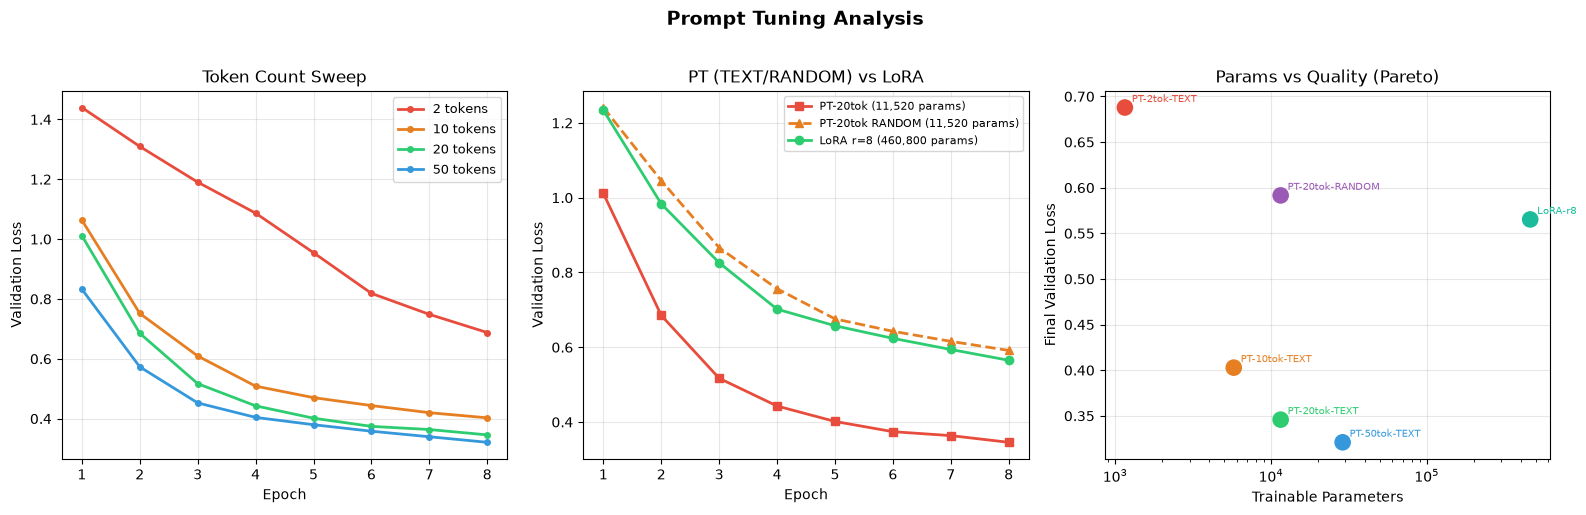

Chart saved → prompt_tuning_comparison.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Prompt Tuning Analysis", fontsize=14, fontweight="bold", y=1.02)

epochs = list(range(1, 9))
colors = ["#e74c3c", "#e67e22", "#2ecc71", "#3498db", "#9b59b6", "#1abc9c"]

# ── Panel 1: Token count sweep — val loss curves ───────────────────────────────
ax = axes[0]
for i, r in enumerate(all_tok_results):
    ax.plot(epochs, r["val_losses"], marker="o", markersize=4, linewidth=2,
            color=colors[i], label=f"{r['num_virtual_tokens']} tokens")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Loss")
ax.set_title("Token Count Sweep")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── Panel 2: PT vs LoRA — training curves ────────────────────────────────────
ax = axes[1]
ax.plot(epochs, pt_standard["val_losses"], marker="s", linewidth=2,
        color="#e74c3c", label=f"PT-20tok ({pt_standard['trainable_params']:,} params)")
ax.plot(epochs, pt_random["val_losses"],   marker="^", linewidth=2, linestyle="--",
        color="#e67e22", label=f"PT-20tok RANDOM ({pt_random['trainable_params']:,} params)")
ax.plot(epochs, lora_result["val_losses"], marker="o", linewidth=2,
        color="#2ecc71", label=f"LoRA r=8 ({lora_result['trainable_params']:,} params)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Loss")
ax.set_title("PT (TEXT/RANDOM) vs LoRA")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# ── Panel 3: Trainable parameters vs final val loss (Pareto view) ─────────────
ax = axes[2]
configs = all_tok_results + [pt_random, lora_result]
param_counts = [r["trainable_params"] for r in configs]
val_losses_final = [r["val_loss"] for r in configs]
labels_for_plot  = [r["label"] for r in configs]

scatter_colors = colors[:len(configs)]
sc = ax.scatter(param_counts, val_losses_final, c=scatter_colors, s=120, zorder=5)
for i, (x, y, lbl) in enumerate(zip(param_counts, val_losses_final, labels_for_plot)):
    ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(5, 4),
                fontsize=7.5, color=scatter_colors[i])
ax.set_xlabel("Trainable Parameters")
ax.set_ylabel("Final Validation Loss")
ax.set_title("Params vs Quality (Pareto)")
ax.set_xscale("log")
ax.grid(True, alpha=0.3)

plt.tight_layout()
out_path = os.path.join(os.path.dirname(os.getcwd()), "notebooks", "prompt_tuning_comparison.png")
# Save relative to notebook location
nb_dir = os.path.dirname(os.path.abspath("06_prompt_tuning.ipynb"))
# Use a robust path
save_path = "prompt_tuning_comparison.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Chart saved → {save_path}")

## 📋 Summary

### What we demonstrated

| Experiment | Key Finding |
|---|---|
| Standard PT (20 tok, TEXT) | Trains only `k × hidden_size` embeddings — everything else frozen |
| Token sweep (2→50) | 2 tokens = failure; 10–20 tokens is the sweet spot for 135M |
| RANDOM vs TEXT init | TEXT init converges faster and achieves lower final loss |
| PT vs LoRA | LoRA wins on quality for small models; PT wins on parameter count |

### When to use Prompt Tuning

✅ **Use it when:**
- You need **many task adapters** sharing one frozen backbone (e.g. per-user personalization)
- Model is **≥ 1B parameters** (more "steerable" capacity)
- Storage/serving cost is critical

⚠️ **Avoid it when:**
- Working with sub-500M models (limited latent capacity)
- Task requires deep domain shift (e.g. new language, new output format)
- You need maximum quality — use LoRA instead

### Up next: Prefix Tuning (`07_prefix_tuning.ipynb`)
Same "frozen model + learned prefix" idea, but prefixes are inserted at **every transformer layer** — not just the input embeddings. More expressive, more parameters.